# 02 — Customer Churn Prediction

> **Synthetic data disclosure.** RetailPulse 360 is fictional. The target `churned_next_90d` is a **synthetic label**, generated probabilistically from historical risk signals with added noise (see `docs/dataset_notes.md`). Model scores show how well the generator's logic can be recovered. They do **not** prove real-world predictive accuracy.

**Objective.** Use only customer history available at the snapshot date (2026-05-31) to rank customers by their risk of churning within the next 90 days, so a retention team with limited capacity knows whom to contact first.

**Approach.** Target and baseline → leakage review → feature selection → stratified split → preprocessing pipelines → Logistic Regression baseline plus two tree ensembles → cross-validation → test evaluation and threshold analysis → interpretation → error analysis → limitations.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from retailpulse360 import data, features, modeling, pipeline, plotting, quality
from retailpulse360.config import RANDOM_STATE, REPORTS_DIR

plotting.apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
%matplotlib inline

In [2]:
tables = data.load_raw_tables()
frame = features.add_corrected_features(data.load_snapshot(), tables["orders"])
print(frame.shape)
frame.head(3)

(6000, 30)


,customer_id,snapshot_date,region,acquisition_channel,preferred_device,loyalty_tier,days_since_signup,recency_days,frequency_12m,monetary_value_12m,avg_order_value_12m,profit_12m,gross_margin_pct_12m,avg_discount_pct_12m,refund_rate_12m,category_diversity_12m,web_sessions_90d,avg_session_minutes_90d,product_views_90d,cart_adds_90d,conversion_rate_90d,cart_add_rate_90d,support_tickets_12m,avg_resolution_hours_12m,avg_csat_12m,refund_requests_12m,churned_next_90d,never_purchased,days_since_last_purchase,no_purchase_12m
0,C000001,2026-05-31,Midwest,Paid Social,Mobile,Silver,351,156.000,2.000,127.090,63.545,41.710,0.328,0.000,0.000,3.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4.000,0.000,0,0,156.000,0
1,C000002,2026-05-31,South,Paid Search,Desktop,Silver,171,201.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,2.000,6.020,5.000,0.000,0.000,0.000,0.000,0.000,4.000,0.000,1,1,171.000,1
2,C000003,2026-05-31,Northeast,Organic Search,Tablet,Bronze,1070,"1,100.000",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4.000,0.000,1,0,458.000,1


## 2. Target distribution and naive baselines

In [3]:
target = frame[features.TARGET]
base_rate = target.mean()
print(f"Churn rate: {base_rate:.1%} ({target.sum():,} of {len(target):,} customers)")
print(f"Accuracy of always predicting 'no churn': {1 - base_rate:.1%}")
print(f"PR-AUC of a random ranking = base rate = {base_rate:.3f}; ROC-AUC of a random ranking = 0.500")

Churn rate: 26.7% (1,599 of 6,000 customers)
Accuracy of always predicting 'no churn': 73.4%
PR-AUC of a random ranking = base rate = 0.267; ROC-AUC of a random ranking = 0.500


About one customer in four churns, so the classes are moderately imbalanced. A model that always predicts "no churn" is about 73% accurate and completely useless. **Accuracy is therefore not used to choose a model.** The evaluation uses ROC-AUC (ranking quality), PR-AUC (precision across recall levels, compared against the 27% base rate), and precision, recall and F1 at a chosen threshold.

## 3. Leakage review

A feature leaks if it would not be available at prediction time or if it encodes the label. Four checks:
1. **Time window.** Every snapshot feature is rebuilt from raw events dated on or before 2026-05-31 (100% match, test-enforced in `tests/test_features.py`).
2. **Identifiers and target.** `customer_id`, `snapshot_date` and `churned_next_90d` are blocked by `features.assert_no_leakage`.
3. **Suspiciously strong features.** No single feature should almost perfectly separate the classes.
4. **Synthetic artifacts.** The recency sentinel discovered in Notebook 01.

In [4]:
reproduction = quality.snapshot_reproduction_check(data.load_snapshot(), features.build_customer_features(tables), features.SNAPSHOT_NUMERIC_FEATURES)
print(f"Snapshot features reproduced from pre-snapshot events: {(reproduction['match_rate'] == 1).sum()} of {len(reproduction)}")
try:
    features.assert_no_leakage(["frequency_12m", "churned_next_90d"])
except ValueError as error:
    print("Leakage guard works:", error)

Snapshot features reproduced from pre-snapshot events: 20 of 20
Leakage guard works: Leakage risk - non-feature columns used as predictors: ['churned_next_90d']


In [5]:
single_feature_auc = {}
for column in features.MODEL_NUMERIC_FEATURES + ["recency_days"]:
    auc = roc_auc_score(target, frame[column])
    single_feature_auc[column] = max(auc, 1 - auc)
pd.Series(single_feature_auc).sort_values(ascending=False).head(8).to_frame("single-feature ROC-AUC")

,single-feature ROC-AUC
recency_days,0.774
days_since_last_purchase,0.772
frequency_12m,0.713
category_diversity_12m,0.694
profit_12m,0.691
monetary_value_12m,0.690
avg_order_value_12m,0.611
no_purchase_12m,0.600


The strongest single features (both recency measures) reach a ROC-AUC of about 0.77 on their own. That is informative without being suspicious: nothing comes close to 1.0, which would point to a leaked label.

In [6]:
recency_bands = pd.cut(frame["days_since_last_purchase"], [-1, 30, 90, 180, 365, 2000], labels=["0-30", "31-90", "91-180", "181-365", "365+"])
frame.groupby(recency_bands, observed=True)[features.TARGET].agg(customers="size", churn_rate="mean")

,customers,churn_rate
days_since_last_purchase,,
0-30,1556,0.098
31-90,1747,0.151
91-180,1374,0.274
181-365,962,0.545
365+,361,0.781


Churn rises steadily with time since the last purchase. This is the expected business pattern, and also how the synthetic label was generated.

**Recency sentinel.** For the 606 customers with no purchase in the 12-month window, the provided `recency_days` equals `days_since_signup + 30` instead of real recency. The models use `days_since_last_purchase` (true recency over all observed history) plus `never_purchased` and `no_purchase_12m` flags. Section 9 tests how sensitive the results are to this choice.

## 4. Feature selection

| Group | Features | Rationale |
|---|---|---|
| Tenure | `days_since_signup` | newer customers may behave differently |
| Recency (corrected) | `days_since_last_purchase`, `never_purchased`, `no_purchase_12m` | the main churn signal; flags separate "never bought" from "lapsed" |
| Frequency / value | `frequency_12m`, `monetary_value_12m`, `avg_order_value_12m`, `profit_12m`, `gross_margin_pct_12m`, `category_diversity_12m` | engagement depth |
| Price sensitivity / experience | `avg_discount_pct_12m`, `refund_rate_12m`, `refund_requests_12m` | dissatisfaction or deal-seeking |
| Digital engagement (90 days) | sessions, minutes, product views, cart adds, conversion and cart-add rates | recent intent |
| Support (12 months) | tickets, resolution hours, CSAT | service experience |
| Attributes | region, acquisition channel, device, loyalty tier (one-hot encoded) | segment differences |

**Excluded:** `customer_id`, `snapshot_date`, the target, and the sentinel `recency_days`.

In [7]:
X, y = modeling.feature_matrix(frame)
print(f"{X.shape[1]} predictors: {len(features.MODEL_NUMERIC_FEATURES)} numeric + {len(features.CATEGORICAL_FEATURES)} categorical")
X.describe().T[["mean", "min", "max"]].head(10)

26 predictors: 22 numeric + 4 categorical


,mean,min,max
days_since_signup,631.820,16.000,"1,246.000"
days_since_last_purchase,120.977,0.000,"1,206.000"
never_purchased,0.053,0.000,1.000
no_purchase_12m,0.101,0.000,1.000
frequency_12m,2.701,0.000,14.000
monetary_value_12m,345.296,0.000,"2,205.770"
avg_order_value_12m,115.486,0.000,858.630
profit_12m,143.915,0.000,909.960
gross_margin_pct_12m,0.382,0.000,0.797
avg_discount_pct_12m,2.582,0.000,25.000


## 5. Train/test split

A **stratified 75/25 split** with a fixed seed (`RANDOM_STATE = 42`) keeps the churn rate equal in both sets and makes the results reproducible. The test set is used **once**, for final evaluation. Model selection and threshold choice use cross-validation on the training set only.

*Why not a time-based split?* The data contains a single snapshot. A time-based validation (train on one snapshot, test on a later one) would be better for production but is not possible here. See Limitations.

In [8]:
X_train, X_test, y_train, y_test = modeling.split_data(X, y)
print(f"Train: {len(X_train):,} customers, churn {y_train.mean():.1%}")
print(f"Test:  {len(X_test):,} customers, churn {y_test.mean():.1%}")

Train: 4,500 customers, churn 26.6%
Test:  1,500 customers, churn 26.7%


## 6. Models and preprocessing pipelines

Each model is a scikit-learn `Pipeline`. Scaling and one-hot encoding are fitted **inside** each training fold, so the test data never influences preprocessing.
- **Logistic Regression** is the interpretable baseline. Numeric features are standardised and categories one-hot encoded.
- **Random Forest** captures non-linear effects and interactions and is robust to outliers.
- **Histogram Gradient Boosting** is a strong tabular learner and a check on whether more model capacity helps.

In [9]:
models = modeling.build_models()
models["Logistic Regression"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{fe

In [10]:
cv_results = modeling.cross_validate_models(models, X_train, y_train)
cv_results

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std
0,Logistic Regression,0.782,0.017,0.591,0.046
1,Random Forest,0.776,0.018,0.587,0.039
2,Gradient Boosting,0.760,0.023,0.567,0.043


In [11]:
chosen = pipeline.select_model(cv_results)
display(Markdown(f"**Selected model: {chosen}.** Rule: choose the best cross-validated PR-AUC, but prefer Logistic Regression when it is within 0.01 of the best, because it is simpler, faster and easier to explain."))

**Selected model: Logistic Regression.** Rule: choose the best cross-validated PR-AUC, but prefer Logistic Regression when it is within 0.01 of the best, because it is simpler, faster and easier to explain.

The models perform within about one standard deviation of each other. The more flexible tree ensembles add no measurable lift, which suggests the churn signal is close to additive (as a generated label would be). The simpler, interpretable model wins.

## 7. Test-set evaluation

In [12]:
test_rows, test_probabilities, fitted = [], {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    fitted[name], test_probabilities[name] = model, proba
    test_rows.append({"model": name, **modeling.classification_metrics(y_test, proba, 0.5)})
pd.DataFrame(test_rows)[["model", "roc_auc", "pr_auc", "brier_score", "accuracy", "precision", "recall", "f1"]]

,model,roc_auc,pr_auc,brier_score,accuracy,precision,recall,f1
0,Logistic Regression,0.785,0.613,0.149,0.799,0.723,0.398,0.513
1,Random Forest,0.772,0.612,0.150,0.801,0.724,0.412,0.525
2,Gradient Boosting,0.769,0.576,0.156,0.785,0.639,0.448,0.526


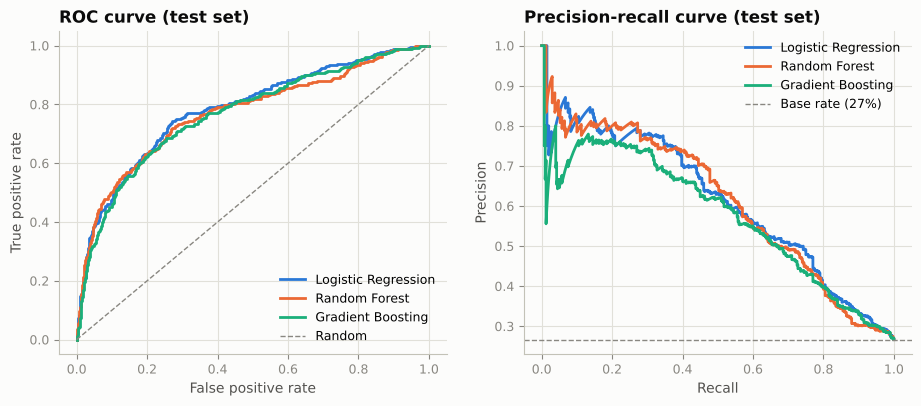

In [13]:
fig = plotting.roc_pr_curves({name: (y_test, proba) for name, proba in test_probabilities.items()}, y_test.mean())
plt.show()

### Choosing a decision threshold

A 0.5 threshold is arbitrary. The threshold is chosen to **maximise F1 on out-of-fold training predictions**, so the test set stays untouched. It is then applied to the test set.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_oof = cross_val_predict(clone(models[chosen]), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
threshold = modeling.best_f1_threshold(y_train, train_oof)
chosen_proba = test_probabilities[chosen]
chosen_metrics = modeling.classification_metrics(y_test, chosen_proba, threshold)
print(f"Chosen threshold: {threshold:.2f}")
pd.DataFrame([modeling.classification_metrics(y_test, chosen_proba, 0.5), chosen_metrics], index=["threshold 0.50", f"threshold {threshold:.2f}"])[["precision", "recall", "f1", "flagged_customers", "true_positives", "false_positives", "false_negatives"]]

Chosen threshold: 0.33


,precision,recall,f1,flagged_customers,true_positives,false_positives,false_negatives
threshold 0.50,0.723,0.398,0.513,220,159,61,241
threshold 0.33,0.576,0.568,0.572,394,227,167,173


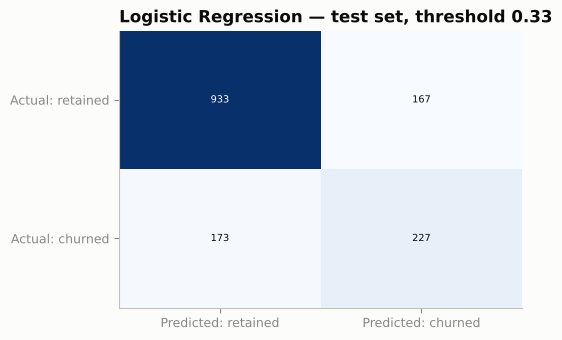

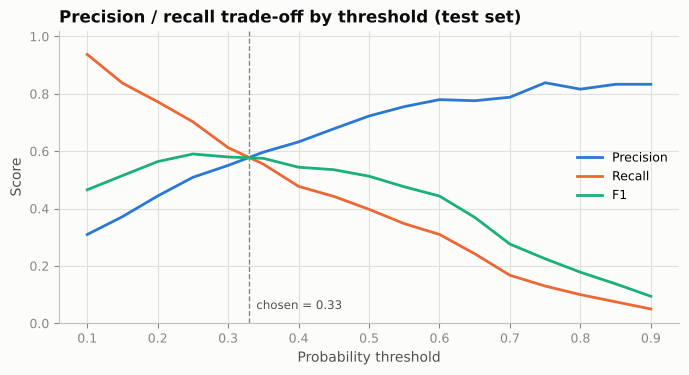

In [15]:
fig = plotting.confusion_matrix_plot(chosen_metrics, f"{chosen} — test set, threshold {threshold:.2f}")
plt.show()
fig = plotting.threshold_plot(modeling.threshold_table(y_test, chosen_proba), threshold)
plt.show()

**The precision–recall trade-off.** Lowering the threshold catches more churners (higher recall), but more of the contacted customers would have stayed anyway (lower precision). The right threshold depends on two things the data does not contain: the **cost of a retention contact** and the **value of a saved customer**.

### Capacity view (labelled assumption)

The data says nothing about retention-team capacity. **Assuming** the team can contact a fixed share of customers, the table shows what share of churners each capacity level would reach:

In [16]:
capacity = modeling.capacity_table(y_test, chosen_proba)
capacity

,contact_share_pct,customers_contacted,churners_reached,precision,recall,lift_vs_random
0,5.000,75,61,0.813,0.152,3.050
1,10.000,150,117,0.780,0.292,2.925
2,15.000,225,159,0.707,0.398,2.650
3,20.000,300,191,0.637,0.477,2.388
4,30.000,450,247,0.549,0.618,2.058
5,40.000,600,297,0.495,0.743,1.856


In [17]:
row = capacity.set_index("contact_share_pct").loc[20.0]
display(Markdown(
    f"*Illustration:* if capacity allowed contacting the riskiest **20%** of customers, about **{row['precision']:.0%}** of those contacted would be true churners, "
    f"against a {y_test.mean():.0%} base rate (**{row['lift_vs_random']:.1f}× lift** over random outreach). Together they would account for **{row['recall']:.0%}** of all churners."
))

*Illustration:* if capacity allowed contacting the riskiest **20%** of customers, about **64%** of those contacted would be true churners, against a 27% base rate (**2.4× lift** over random outreach). Together they would account for **48%** of all churners.

## 8. Interpretation

**Logistic-regression coefficients** are shown on standardised features: the change in log-odds for a one-standard-deviation increase. Value features such as frequency, monetary value and profit are strongly correlated, so their individual coefficients can split or even flip sign. **Permutation importance** on the test set, which measures how much ROC-AUC falls when a feature is shuffled, is the more reliable view of what matters.

In [18]:
modeling.logistic_coefficients(fitted["Logistic Regression"]).head(12)

,feature,coefficient,odds_ratio
0,days_since_last_purchase,0.993,2.698
1,frequency_12m,-0.465,0.628
2,no_purchase_12m,-0.356,0.701
3,loyalty_tier_Gold,-0.309,0.734
4,profit_12m,0.224,1.251
5,preferred_device_Desktop,-0.221,0.802
6,loyalty_tier_Platinum,-0.204,0.816
7,preferred_device_Mobile,-0.202,0.817
8,region_Midwest,-0.202,0.817
9,never_purchased,0.185,1.204


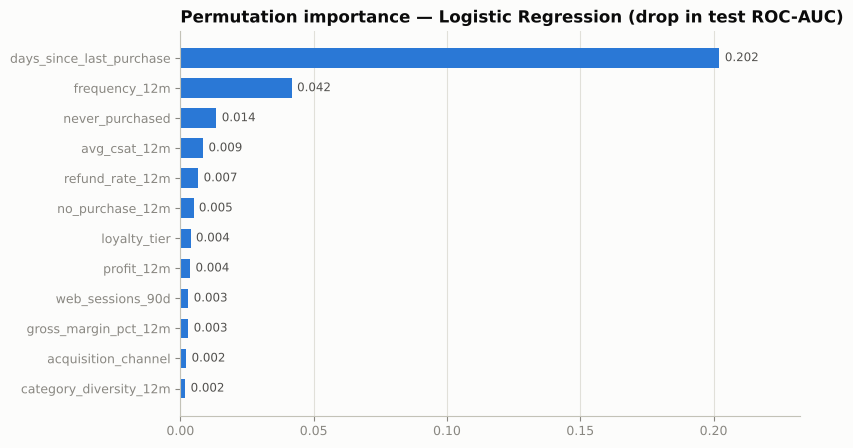

In [19]:
importance = modeling.permutation_importance_table(fitted[chosen], X_test, y_test)
fig, ax = plt.subplots(figsize=(8, 5))
plotting.barh_chart(importance.head(12), "feature", "importance_mean", f"Permutation importance — {chosen} (drop in test ROC-AUC)", fmt="{:.3f}", ax=ax)
plt.show()

In [20]:
frame[["frequency_12m", "monetary_value_12m", "profit_12m", "category_diversity_12m"]].corr()

,frequency_12m,monetary_value_12m,profit_12m,category_diversity_12m
frequency_12m,1.000,0.833,0.835,0.797
monetary_value_12m,0.833,1.000,0.983,0.770
profit_12m,0.835,0.983,1.000,0.763
category_diversity_12m,0.797,0.770,0.763,1.000


**Reading.** Time since the last purchase is by far the most important driver, followed by purchase frequency and whether the customer has ever bought. Loyalty tier, refund behaviour and CSAT add smaller amounts. Digital-engagement features contribute little once purchase history is known. The high correlations above explain why coefficient signs for value features should not be read one at a time.

## 9. Error analysis, calibration and sensitivity

In [21]:
test_view = X_test.assign(actual=y_test.to_numpy(), score=chosen_proba, predicted=(chosen_proba >= threshold).astype(int))
test_view["outcome"] = np.select(
    [(test_view.actual == 1) & (test_view.predicted == 1), (test_view.actual == 0) & (test_view.predicted == 1), (test_view.actual == 1) & (test_view.predicted == 0)],
    ["True positive", "False positive", "False negative"], default="True negative")
test_view.groupby("outcome")[["days_since_last_purchase", "frequency_12m", "monetary_value_12m", "web_sessions_90d", "support_tickets_12m", "score"]].mean()

,days_since_last_purchase,frequency_12m,monetary_value_12m,web_sessions_90d,support_tickets_12m,score
outcome,,,,,,
False negative,76.798,2.757,334.635,2.069,0.514,0.194
False positive,239.449,1.455,188.567,1.922,0.455,0.496
True negative,57.226,3.387,431.318,2.271,0.563,0.149
True positive,330.048,0.780,95.900,1.943,0.401,0.619


**False negatives** (missed churners) look like active customers: recent purchases and higher frequency. On these features they are almost indistinguishable from true negatives, so better features (such as the reasons customers leave) would be needed to catch them. Part of this error is the noise built into the synthetic label. **False positives** look like true churners (long inactivity) but did not churn. In practice these are the customers a retention offer might waste money on.

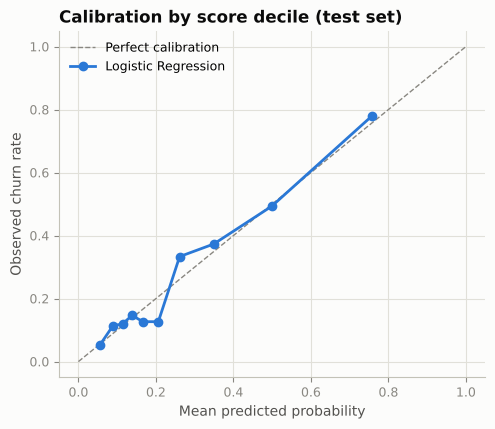

,predicted,actual
decile,,
1,0.056,0.053
2,0.089,0.113
3,0.114,0.120
4,0.138,0.147
5,0.166,0.127
6,0.206,0.127
7,0.261,0.333
8,0.349,0.373
9,0.499,0.493


In [22]:
deciles = pd.qcut(chosen_proba, 10, labels=False, duplicates="drop")
calibration = pd.DataFrame({"decile": deciles + 1, "predicted": chosen_proba, "actual": y_test.to_numpy()}).groupby("decile").mean()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot([0, 1], [0, 1], color=plotting.INK_MUTED, linestyle="--", linewidth=1, label="Perfect calibration")
ax.plot(calibration["predicted"], calibration["actual"], color=plotting.PRIMARY_COLOR, marker="o", label=chosen)
ax.set(title="Calibration by score decile (test set)", xlabel="Mean predicted probability", ylabel="Observed churn rate")
ax.legend(loc="upper left")
plt.show()
calibration

Predicted probabilities track observed churn reasonably well. The lowest and highest deciles are close, and the middle deciles deviate by a few percentage points. The scores can be read as rough probabilities, and recalibration would be needed in production. This is useful when estimating how many churners a campaign would reach.

In [23]:
sensitivity = {}
for label, numeric in [("Corrected recency + flags (used)", features.MODEL_NUMERIC_FEATURES), ("Provided sentinel recency_days", features.SNAPSHOT_NUMERIC_FEATURES)]:
    Xs, ys = modeling.feature_matrix(frame, numeric=numeric)
    a, b, c, d = modeling.split_data(Xs, ys)
    model = modeling.build_models(numeric=numeric)["Logistic Regression"].fit(a, c)
    sensitivity[label] = roc_auc_score(d, model.predict_proba(b)[:, 1])
pd.Series(sensitivity).to_frame("test ROC-AUC (Logistic Regression)")

,test ROC-AUC (Logistic Regression)
Corrected recency + flags (used),0.785
Provided sentinel recency_days,0.780


Replacing the sentinel with true recency does not reduce performance, so the model does not depend on the artifact. The corrected version is also the one that would carry over to real data.

## 10. Consistency with the saved project outputs

In [24]:
saved = json.loads((REPORTS_DIR / "model_metrics.json").read_text())["churn"]
assert saved["chosen_model"] == chosen
assert abs(saved["threshold"] - threshold) < 1e-9
assert abs(saved["test_metrics_at_threshold"]["roc_auc"] - chosen_metrics["roc_auc"]) < 1e-9
print("Notebook results match reports/model_metrics.json (written by scripts/run_pipeline.py).")
display(Markdown(
    f"**Final model:** {chosen}. Test ROC-AUC **{chosen_metrics['roc_auc']:.3f}**, PR-AUC **{chosen_metrics['pr_auc']:.3f}** (base rate {y_test.mean():.3f}). "
    f"At threshold {threshold:.2f}: precision **{chosen_metrics['precision']:.2f}**, recall **{chosen_metrics['recall']:.2f}**, F1 **{chosen_metrics['f1']:.2f}**. "
    f"CV ROC-AUC {cv_results.set_index('model').loc[chosen, 'cv_roc_auc_mean']:.3f} ± {cv_results.set_index('model').loc[chosen, 'cv_roc_auc_std']:.3f}."
))

Notebook results match reports/model_metrics.json (written by scripts/run_pipeline.py).


**Final model:** Logistic Regression. Test ROC-AUC **0.785**, PR-AUC **0.613** (base rate 0.267). At threshold 0.33: precision **0.58**, recall **0.57**, F1 **0.57**. CV ROC-AUC 0.782 ± 0.017.

## 11. Business implications

- **Use the score to rank customers, not as a verdict.** It prioritises outreach when capacity is limited. The capacity table shows the trade-off at each contact volume.
- **Recency is the main lever.** A rule such as "no purchase in 90+ days" already captures much of the signal, and the model adds frequency, value and tier on top of it.
- **Prove outreach works before scaling.** A score predicts who is at risk, not who can be saved. Randomly hold out some high-risk customers from each campaign and compare retention between the two groups.
- **Choose the threshold from costs.** With a contact cost *c* and a saved-customer value *v*, contacting pays off on average when precision × (probability the offer works) × *v* > *c*. These inputs are not in the data and would have to come from the business.

## 12. Limitations

1. **Synthetic label.** Performance reflects the data generator, not real customer behaviour.
2. **Single snapshot.** There is no out-of-time validation. Production use would need training on several historical snapshots, testing on a later one, and monitoring for drift.
3. **Static attributes.** Loyalty tier and similar fields have no history. If they were updated after the snapshot, they would leak information.
4. **Missing drivers.** There is no data on competitor offers, delivery experience per order, product reviews or contact history.
5. **Uplift not modelled.** Predicting churn is not the same as predicting who responds to an offer. That needs experiment data.